# Data Mining Project

### Data Understanding & Preparation
* #### Data Semantics
  - Introduce the variables with their meaning and characteristics;
* #### Distribution of the variables and statistics
  - Explore (single, pairs of…) variables quantitatively (e.g., statistics, distributions);
* #### Assessing data quality
  - Are present errors, outliers, missing values, semantic inconsistencies, etc?
* #### Variable transformations
  - Is it better to use for further modules transformed variables (e.g., log-transformated)?
* #### Pairwise correlations and eventual elimination of variables
  - Matrix correlation (analyse high correlated variables);

### Informazioni Generali
* **Corso:** Data Mining
* **Università:** Università di Pisa
* **Anno Accademico:** 2024/2025

### Autore
* **Studente:** Giuseppe Muschetta

### Dataset Utilizzato
* **Nome:** IMDb Dataset (Data Matrix)
* **Descrizione:** Dataset consisting of 21909 points in 23 dimensions

In [1]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast

In [2]:
# Global style setting for Seaborn and matplotlib plots
plt.style.use("dark_background")
sns.set_theme(
    style="darkgrid",
    context="notebook",
    palette="icefire",  # rocket, mako, crest, vlag, flare
    font="sans-serif",
    font_scale=1.1
)

# Other palette examples:
# dark mode: icefire, rocket, mako, crest, vlag, flare
# white theme: viridis, magma, plasma, inferno, cividis,

# Ottimizzazione dei caratteri (solo se vuoi)
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.edgecolor'] = 'white'
plt.rcParams['axes.labelcolor'] = 'white'
plt.rcParams['xtick.color'] = 'lightgray'
plt.rcParams['ytick.color'] = 'lightgray'
plt.rcParams['text.color'] = 'white'
plt.rcParams['figure.facecolor'] = '#111111'
plt.rcParams['axes.facecolor'] = '#111111'
plt.rcParams['savefig.facecolor'] = '#111111'

In [3]:
# Create Directory for Plots ---
# To keep our project organized, we'll save all generated plots to a specific
# directory. This code creates a 'plots' directory if it doesn't already exist.

plots_dir = 'plots_understanding/'

if not os.path.exists(plots_dir):
    os.makedirs(plots_dir, exist_ok=True)
    print(f"Directory {plots_dir} created successfully.")
else:
    print(f"Directory {plots_dir} already exists.")

# Load the dataset ---
# Load the dataset from the provided CSV file into a pandas DataFrame, which is
# the primary data structure we will use for our analysis.

# Define the file path
dataset_dir = 'dataset/'
dataset_train = 'train.csv'
dataset_test = 'test.csv'

# Load the data
try:
    df_train = pd.read_csv(dataset_dir + dataset_train)
    print(f"dataset '{dataset_train}' loaded successfully.")
    print(f"The dataset contains {df_train.shape[0]} rows and {df_train.shape[1]} columns.")
    df_test = pd.read_csv(dataset_dir + dataset_test)
    print(f"dataset '{dataset_test}' loaded successfully.")
    print(f"The dataset contains {df_test.shape[0]} rows and {df_test.shape[1]} columns.")
except FileNotFoundError:
    print(f"Error: The dataset in the dir '{dataset_dir}' was not found. Please check the file path.")
    exit(1)


Directory plots_understanding/ already exists.
dataset 'train.csv' loaded successfully.
The dataset contains 16431 rows and 23 columns.
dataset 'test.csv' loaded successfully.
The dataset contains 5478 rows and 23 columns.


In [4]:
df_train.head()

,originalTitle,rating,startYear,endYear,runtimeMinutes,awardWins,numVotes,worstRating,bestRating,totalImages,...,titleType,awardNominationsExcludeWins,canHaveEpisodes,isRatable,isAdult,numRegions,userReviewsTotal,ratingCount,countryOfOrigin,genres
0,Neogenic Nightmare Chapter 3: Hydro-Man,"(7, 8]",1995,\N,\N,0.0,779,1,10,1,...,tvEpisode,0,False,True,0,1,0,781,['US'],"Action,Adventure,Animation"
1,Looping,"(5, 6]",1982,\N,\N,0.0,11,1,10,1,...,videoGame,0,False,True,0,1,0,11,['XWG'],Action
2,Idealnaya para,"(5, 6]",1992,\N,\N,0.0,38,1,10,1,...,movie,0,False,True,0,1,1,38,['RU'],Comedy
3,MasterChef Celebrity México,"(5, 6]",2021,\N,\N,0.0,15,1,10,22,...,tvSeries,0,True,True,0,1,0,15,['MX'],Reality-TV
4,Seutateueob,"(7, 8]",2020,2020,80,1.0,15718,1,10,347,...,tvSeries,1,True,True,0,32,452,15746,['KR'],"Comedy,Drama,Romance"


In [5]:
df_test.head()

,originalTitle,rating,startYear,endYear,runtimeMinutes,awardWins,numVotes,worstRating,bestRating,totalImages,...,titleType,awardNominationsExcludeWins,canHaveEpisodes,isRatable,isAdult,numRegions,userReviewsTotal,ratingCount,countryOfOrigin,genres
0,Geologist of Animal Collective Performs Live a...,"(9, 10]",2015,\N,21,0.0,15,1,10,7,...,video,0,False,True,0,1,0,15,['US'],"Music,Short"
1,Shan gou 1999,"(4, 5]",1999,\N,\N,0.0,304,1,10,10,...,movie,0,False,True,0,4,8,304,['HK'],Horror
2,The Craftsman: Preserving the Last Higgins Boat,"(8, 9]",2023,\N,\N,0.0,10,1,10,2,...,tvSpecial,0,False,True,0,1,0,10,['US'],Reality-TV
3,Week 3: Tuesday,"(6, 7]",2020,\N,\N,0.0,11,1,10,0,...,tvEpisode,0,False,True,0,1,0,11,['GB'],Game-Show
4,Traumhaus,"(5, 6]",1999,\N,90,NaN,145,1,10,2,...,tvEpisode,0,False,True,0,1,0,145,['DE'],"Crime,Drama,Mystery"


In [6]:
df_train.info(verbose=True, memory_usage='deep',show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16431 entries, 0 to 16430
Data columns (total 23 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   originalTitle                16431 non-null  object 
 1   rating                       16431 non-null  object 
 2   startYear                    16431 non-null  int64  
 3   endYear                      16431 non-null  object 
 4   runtimeMinutes               16431 non-null  object 
 5   awardWins                    13813 non-null  float64
 6   numVotes                     16431 non-null  int64  
 7   worstRating                  16431 non-null  int64  
 8   bestRating                   16431 non-null  int64  
 9   totalImages                  16431 non-null  int64  
 10  totalVideos                  16431 non-null  int64  
 11  totalCredits                 16431 non-null  int64  
 12  criticReviewsTotal           16431 non-null  int64  
 13  titleType       

In [7]:
df_train.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
startYear,16431.0,1991.867081,26.120690,1878.0,1978.0,1997.0,2013.0,2024.0
awardWins,13813.0,0.491855,2.974264,0.0,0.0,0.0,0.0,145.0
numVotes,16431.0,1492.153551,20137.708096,5.0,15.0,36.0,148.5,966565.0
worstRating,16431.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
bestRating,16431.0,10.000000,0.000000,10.0,10.0,10.0,10.0,10.0
totalImages,16431.0,11.477025,74.254261,0.0,1.0,1.0,6.0,3504.0
totalVideos,16431.0,0.271499,3.115448,0.0,0.0,0.0,0.0,258.0
totalCredits,16431.0,61.341976,174.017450,0.0,16.0,34.0,65.0,15742.0
criticReviewsTotal,16431.0,2.785527,15.411389,0.0,0.0,0.0,1.0,533.0
awardNominationsExcludeWins,16431.0,0.558883,3.955372,0.0,0.0,0.0,0.0,197.0


In [8]:
#Null Values
for col in df_train.select_dtypes(include=np.number).columns:
    print(f"Column '{col}': {df_train[col].isna().sum()} null values")
    # print(df[col].value_counts())
    # print("")

Column 'startYear': 0 null values
Column 'awardWins': 2618 null values
Column 'numVotes': 0 null values
Column 'worstRating': 0 null values
Column 'bestRating': 0 null values
Column 'totalImages': 0 null values
Column 'totalVideos': 0 null values
Column 'totalCredits': 0 null values
Column 'criticReviewsTotal': 0 null values
Column 'awardNominationsExcludeWins': 0 null values
Column 'isAdult': 0 null values
Column 'numRegions': 0 null values
Column 'userReviewsTotal': 0 null values
Column 'ratingCount': 0 null values


In [9]:
for col in df_train.select_dtypes(include=['object']).columns:
    print(f"Column '{col}': {df_train[col].isna().sum()} null values")

Column 'originalTitle': 0 null values
Column 'rating': 0 null values
Column 'endYear': 0 null values
Column 'runtimeMinutes': 0 null values
Column 'titleType': 0 null values
Column 'countryOfOrigin': 0 null values
Column 'genres': 0 null values


In [10]:
# Ci sono colonne che palesemente hanno un tipo diverso da quello atteso.
"""
'runtimeMinutes' is type object, but it is obviously of type int
'awardWins' is type float, but it is obviously of type int (since an award cannot be a fraction)'
since both 'canHaveEpisodes' and 'isRatable' are type bool i will convert 'isAdult' of type int in bool format for better correlation with other categoricals variables
"""

"\n'runtimeMinutes' is type object, but it is obviously of type int\n'awardWins' is type float, but it is obviously of type int (since an award cannot be a fraction)'\nsince both 'canHaveEpisodes' and 'isRatable' are type bool i will convert 'isAdult' of type int in bool format for better correlation with other categoricals variables\n"

In [11]:
df_train['isAdult'] = df_train['isAdult'].astype(bool)
df_test['isAdult'] = df_test['isAdult'].astype(bool)

#### DISTRIBUZIONE VARIABLI CATEGORICHE

/var/folders/4l/s_d8z1kx7h762hwfcv4xhtsh0000gn/T/ipykernel_72773/1135999370.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/var/folders/4l/s_d8z1kx7h762hwfcv4xhtsh0000gn/T/ipykernel_72773/1135999370.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/var/folders/4l/s_d8z1kx7h762hwfcv4xhtsh0000gn/T/ipykernel_72773/1135999370.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10.index, y=top_10.values, ax=ax, palette='icefire')
/var/folders/4l/s_d8z1kx7h762hwfcv4xhtsh0000gn/T/ipykernel_72773/1135999370.py:47: FutureWarnin

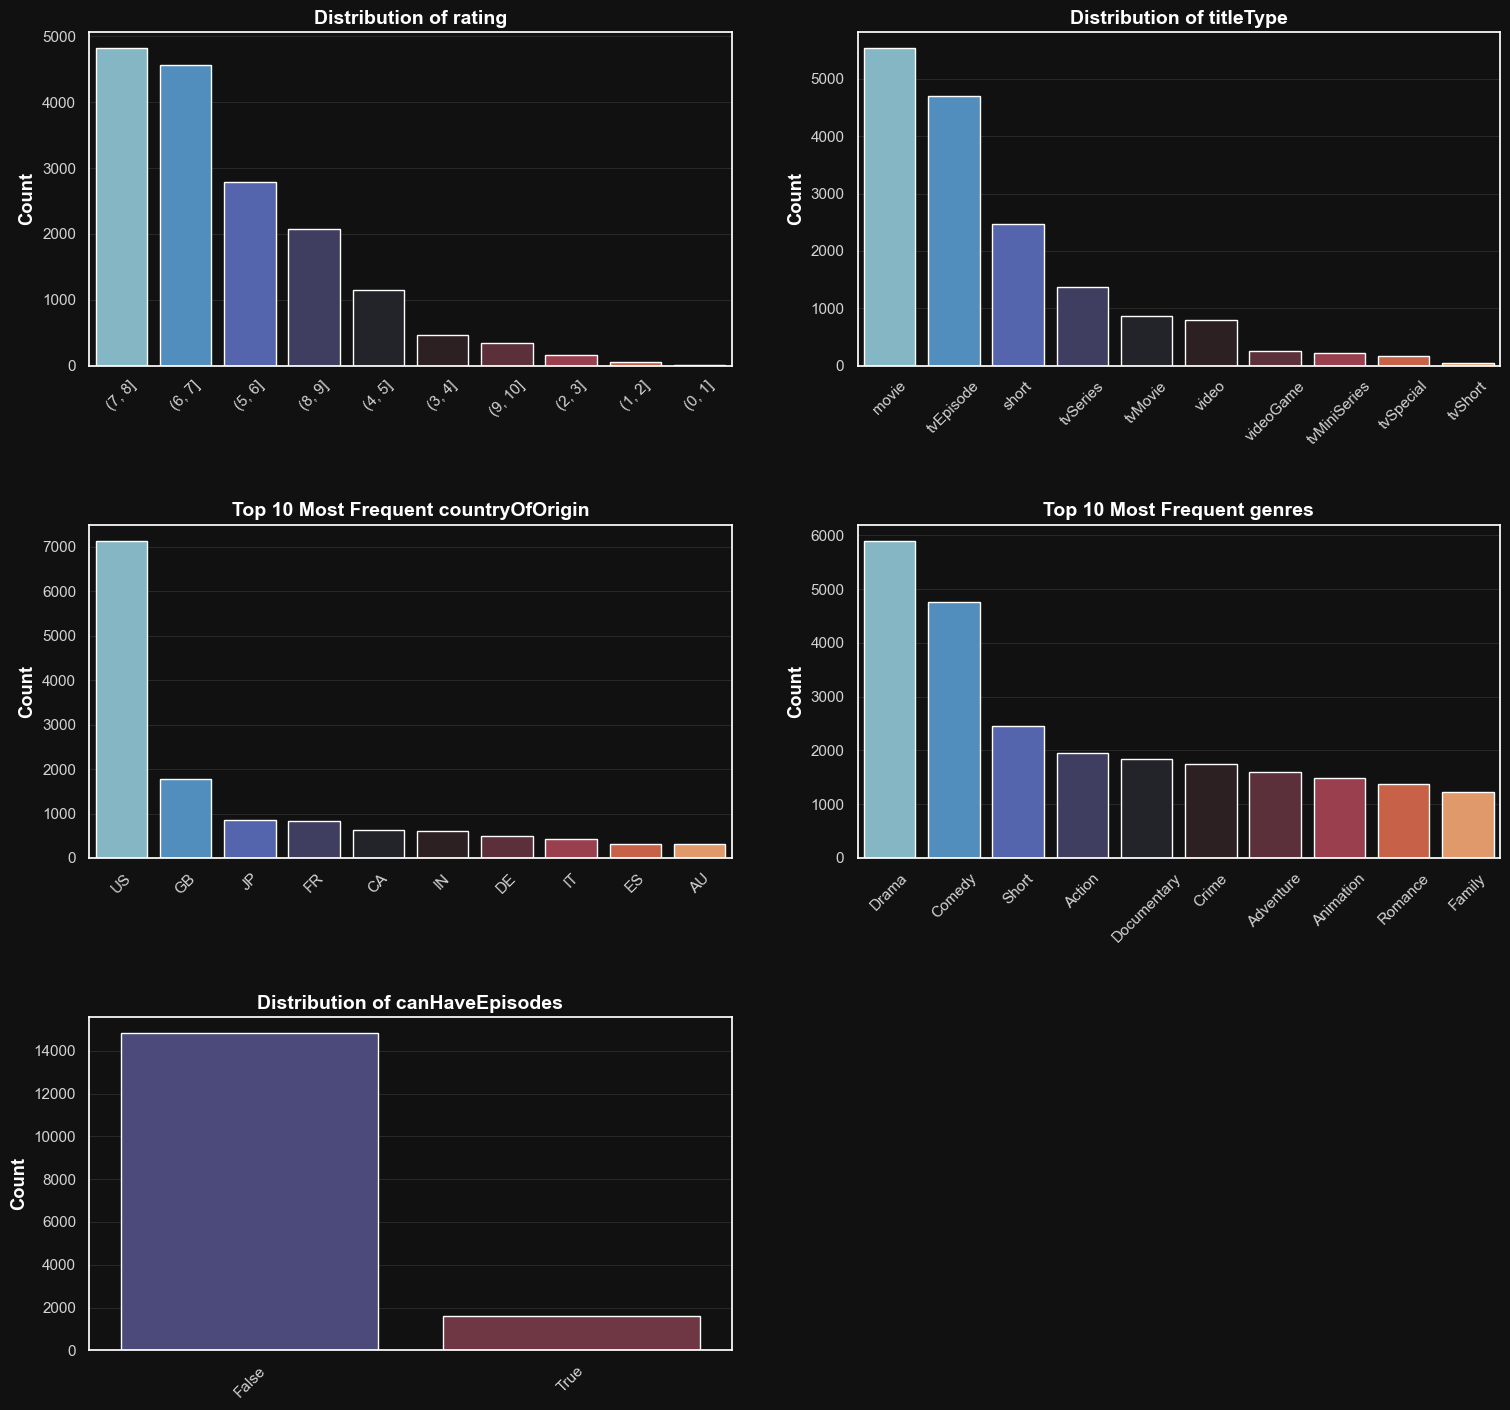

In [12]:
# --- Plotting Categorical Variables ---

categorical_columns = [
    'rating',
    'titleType',
    'countryOfOrigin',
    'genres',
    'canHaveEpisodes'
]

# Plot styling settings
plt.rcParams['grid.color'] = 'gray'
plt.rcParams['grid.linewidth'] = 0.5
plt.rcParams['grid.alpha'] = 0.3

# Set up the subplot grid
n_cols = 2
# Ensure enough rows are created for all plots
n_rows = int(np.ceil(len(categorical_columns) / n_cols))
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(16, 5 * n_rows))
axes = axes.flatten()  # Flatten for easy linear indexing

# --- Loop and Plot ---
for idx, col in enumerate(categorical_columns):
    ax = axes[idx]

    # --- Special handling for multi-label columns ---
    if col in ['genres', 'countryOfOrigin']:
        # Drop missing values and copy to avoid SettingWithCopyWarning
        data_to_plot = df_train[[col]].dropna().copy()

        # Parse the string-formatted lists into actual lists
        if col == 'genres':
            # Handles 'Action,Adventure,Drama'
            data_to_plot[col] = data_to_plot[col].str.split(',')
        else: # countryOfOrigin
            # Safely evaluates '["US", "GB"]' into a list
            data_to_plot[col] = data_to_plot[col].apply(ast.literal_eval)

        # Explode the lists into separate rows for each label
        exploded_data = data_to_plot.explode(col)

        # Get the top 10 most frequent labels for plotting
        top_10 = exploded_data[col].value_counts().nlargest(10)

        # Create the plot for the top 10
        sns.barplot(x=top_10.index, y=top_10.values, ax=ax, palette='icefire')
        ax.set_title(f"Top 10 Most Frequent {col}", fontsize=14, weight='bold')
        ax.set_ylabel('Count')

    # --- Standard handling for single-label columns ---
    else:
        sns.countplot(
            x=col,
            data=df_train,
            ax=ax,
            order=df_train[col].value_counts().index, # Order by frequency
            palette='icefire'
        )
        ax.set_title(f"Distribution of {col}", fontsize=14, weight='bold')
        ax.set_ylabel('Count')

    ax.tick_params(axis='x', rotation=45, labelsize=11)
    ax.tick_params(axis='y', labelsize=11)
    ax.set_xlabel('') # Remove x-axis label for cleaner look

# Remove any empty subplots if the number of plots is odd
for j in range(len(categorical_columns), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout(pad=3.0)
# Make sure the 'plots_understanding' directory exists
plt.savefig(plots_dir + "categorical_distribution.png", dpi=300)
plt.show()



#### CORRELAZIONI VARIABILI CATEGORICHE

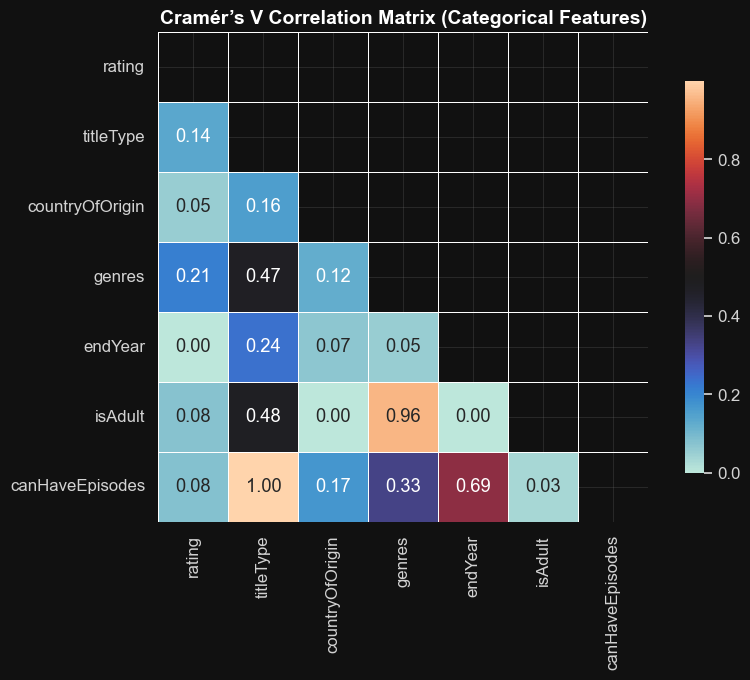

In [13]:
#### Correlazione Variabili Categoriche con Cramer's V

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

categorical_columns = [
    'rating',
    'titleType',
    'countryOfOrigin',
    'genres',
    'endYear',
    'isAdult',
    'canHaveEpisodes',
    # 'isRatable' avendo zero variance (un solo valore) non plotta la matrice di correlazione
]

# Funzione per calcolare Cramér’s V tra due variabili categoriche
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2, _, _, _ = chi2_contingency(confusion_matrix, correction=False)
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2_corr = max(0, phi2 - ((k-1)*(r-1)) / (n-1))
    r_corr = r - ((r-1)**2)/(n-1)
    k_corr = k - ((k-1)**2)/(n-1)
    return np.sqrt(phi2_corr / min((k_corr-1), (r_corr-1)))


# Calcola la matrice di Cramér's V
n = len(categorical_columns)
cramers_matrix = np.zeros((n, n))

for i in range(n):
    for j in range(i):
        v = cramers_v(df_train[categorical_columns[i]], df_train[categorical_columns[j]])
        cramers_matrix[i, j] = v
        cramers_matrix[j, i] = v  # Simmetrico

# Crea DataFrame della matrice
cramer_df = pd.DataFrame(cramers_matrix, index=categorical_columns, columns=categorical_columns)

# Maschera triangolo superiore + diagonale
mask = np.triu(np.ones_like(cramer_df, dtype=bool))

# Visualizzazione heatmap con Seaborn in stile dark
plt.figure(figsize=(9, 7))
sns.heatmap(
    cramer_df,
    mask=mask,
    cmap="icefire",  # Palette leggibile su dark
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
)

plt.title("Cramér’s V Correlation Matrix (Categorical Features)", fontsize=14, weight="bold")
plt.tight_layout()
plt.savefig(plots_dir + "cramers_v_matrix.png", dpi=300)
plt.show()




In [14]:
# da qui capiamo che canHaveEpisodes e isAdult si possono eliminare perchè ridondanti ed eliminiamo anche 'isRatable' avendo varianza zero
df_train.drop(columns=['canHaveEpisodes', 'isAdult', 'isRatable'], inplace=True)
df_test.drop(columns=['canHaveEpisodes', 'isAdult', 'isRatable'], inplace=True)

#### Trasformazioni variabili categoriche

In [15]:
# --- Categorical Variable Processing ---
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
import ast

# --- 1. Ordinal Encoding for 'rating' ---
print("Processing 'rating' column...")

# Define the explicit order of the rating categories
rating_order = [
    '(0, 1]', '(1, 2]', '(2, 3]', '(3, 4]', '(4, 5]',
    '(5, 6]', '(6, 7]', '(7, 8]', '(8, 9]', '(9, 10]'
]

# Initialize and fit the encoder ONLY on the training data
ordinal_encoder = OrdinalEncoder(categories=[rating_order])
ordinal_encoder.fit(df_train[['rating']])

# Transform both train and test sets
df_train['rating_encoded'] = ordinal_encoder.transform(df_train[['rating']])
df_test['rating_encoded'] = ordinal_encoder.transform(df_test[['rating']])


# --- 2. One-Hot Encoding for 'titleType' ---
print("Processing 'titleType' column...")

# Initialize the encoder. 'handle_unknown' prevents errors if test set has new categories.
one_hot_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# Fit on train data and transform both sets
ohe_train_data = one_hot_encoder.fit_transform(df_train[['titleType']])
ohe_test_data = one_hot_encoder.transform(df_test[['titleType']])

# Create DataFrames with the new one-hot encoded columns
ohe_train_df = pd.DataFrame(ohe_train_data, index=df_train.index, columns=one_hot_encoder.get_feature_names_out(['titleType']))
ohe_test_df = pd.DataFrame(ohe_test_data, index=df_test.index, columns=one_hot_encoder.get_feature_names_out(['titleType']))

# Concatenate the new columns to the main DataFrames
df_train = pd.concat([df_train, ohe_train_df], axis=1)
df_test = pd.concat([df_test, ohe_test_df], axis=1)


# --- 3. Multi-Label Binarization for 'genres' and 'countryOfOrigin' (Top 10) ---
multi_label_cols = ['genres', 'countryOfOrigin']

for col in multi_label_cols:
    print(f"Processing '{col}' column (Top 10)...")

    # --- Step A: Identify Top 10 Labels from the Training Set ---
    # Create a temporary series, parse it, and explode it
    temp_series = df_train[col].dropna()
    if col == 'genres':
        temp_series = temp_series.str.split(',')
    else: # countryOfOrigin
        temp_series = temp_series.apply(ast.literal_eval)

    exploded_series = temp_series.explode()
    top_10_labels = exploded_series.value_counts().nlargest(10).index.tolist()
    print(f"Top 10 for '{col}': {top_10_labels}")

    # --- Step B: Create Binary Columns for Top 10 in both Train and Test sets ---
    for label in top_10_labels:
        # For train set
        df_train[f'{col}_{label}'] = df_train[col].apply(lambda x: 1 if isinstance(x, str) and label in x else 0)
        # For test set
        df_test[f'{col}_{label}'] = df_test[col].apply(lambda x: 1 if isinstance(x, str) and label in x else 0)


# --- 4. Final Cleanup ---
# Drop the original categorical columns that have now been encoded
cols_to_drop_categorical = ['rating', 'titleType', 'genres', 'countryOfOrigin']
df_train = df_train.drop(columns=cols_to_drop_categorical, errors='ignore')
df_test = df_test.drop(columns=cols_to_drop_categorical, errors='ignore')

print("\nCategorical processing complete.")
display(df_train.head())

Processing 'rating' column...
Processing 'titleType' column...
Processing 'genres' column (Top 10)...
Top 10 for 'genres': ['Drama', 'Comedy', 'Short', 'Action', 'Documentary', 'Crime', 'Adventure', 'Animation', 'Romance', 'Family']
Processing 'countryOfOrigin' column (Top 10)...
Top 10 for 'countryOfOrigin': ['US', 'GB', 'JP', 'FR', 'CA', 'IN', 'DE', 'IT', 'ES', 'AU']

Categorical processing complete.


,originalTitle,startYear,endYear,runtimeMinutes,awardWins,numVotes,worstRating,bestRating,totalImages,totalVideos,...,countryOfOrigin_US,countryOfOrigin_GB,countryOfOrigin_JP,countryOfOrigin_FR,countryOfOrigin_CA,countryOfOrigin_IN,countryOfOrigin_DE,countryOfOrigin_IT,countryOfOrigin_ES,countryOfOrigin_AU
0,Neogenic Nightmare Chapter 3: Hydro-Man,1995,\N,\N,0.0,779,1,10,1,0,...,1,0,0,0,0,0,0,0,0,0
1,Looping,1982,\N,\N,0.0,11,1,10,1,0,...,0,0,0,0,0,0,0,0,0,0
2,Idealnaya para,1992,\N,\N,0.0,38,1,10,1,0,...,0,0,0,0,0,0,0,0,0,0
3,MasterChef Celebrity México,2021,\N,\N,0.0,15,1,10,22,0,...,0,0,0,0,0,0,0,0,0,0
4,Seutateueob,2020,2020,80,1.0,15718,1,10,347,2,...,0,0,0,0,0,0,0,0,0,0


In [16]:
df_train

,originalTitle,startYear,endYear,runtimeMinutes,awardWins,numVotes,worstRating,bestRating,totalImages,totalVideos,...,countryOfOrigin_US,countryOfOrigin_GB,countryOfOrigin_JP,countryOfOrigin_FR,countryOfOrigin_CA,countryOfOrigin_IN,countryOfOrigin_DE,countryOfOrigin_IT,countryOfOrigin_ES,countryOfOrigin_AU
0,Neogenic Nightmare Chapter 3: Hydro-Man,1995,\N,\N,0.0,779,1,10,1,0,...,1,0,0,0,0,0,0,0,0,0
1,Looping,1982,\N,\N,0.0,11,1,10,1,0,...,0,0,0,0,0,0,0,0,0,0
2,Idealnaya para,1992,\N,\N,0.0,38,1,10,1,0,...,0,0,0,0,0,0,0,0,0,0
3,MasterChef Celebrity México,2021,\N,\N,0.0,15,1,10,22,0,...,0,0,0,0,0,0,0,0,0,0
4,Seutateueob,2020,2020,80,1.0,15718,1,10,347,2,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16426,Caprices,1942,\N,\N,0.0,73,1,10,4,0,...,0,0,0,1,0,0,0,0,0,0
16427,Haar Jeet,1990,\N,\N,0.0,15,1,10,2,0,...,0,0,0,0,0,1,0,0,0,0
16428,Kotigobba 3,2021,\N,140,0.0,2560,1,10,39,3,...,0,0,0,0,0,1,0,0,0,0
16429,Ator l'invincibile,1982,\N,\N,0.0,3011,1,10,52,1,...,0,0,0,0,0,0,0,1,0,0


#### DISTRIBUZIONE VARIABILI NUMERICHE

#### Imputazione colonna 'awardWins' mediante iterativeImputer

In [17]:
# The experimental import is required for IterativeImputer in some scikit-learn versions
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
import pandas as pd

# 1. Select the features for imputation based on the correlation matrix
# We choose variables that are most correlated with 'awardWins'
imputation_features = [
    'awardWins',            # The column we want to fill
    'criticReviewsTotal',   # Correlation: 0.36
    'numVotes',             # Correlation: 0.35
    'userReviewsTotal',     # Correlation: 0.28
    'numRegions'            # Correlation: 0.28
]

# Print number of NaNs before imputation
print(f"NaNs in 'awardWins' (train) before imputation: {df_train['awardWins'].isnull().sum()}")
print(f"NaNs in 'awardWins' (test) before imputation: {df_test['awardWins'].isnull().sum()}")


# 2. Initialize the IterativeImputer
# max_iter controls how many imputation rounds are performed.
imputer = IterativeImputer(max_iter=10, random_state=42)

# 3. Fit the imputer ONLY on the training data
imputer.fit(df_train[imputation_features])

# 4. Transform both the train and test sets
# The transform method returns a NumPy array with the imputed values
imputed_train_data = imputer.transform(df_train[imputation_features])
imputed_test_data = imputer.transform(df_test[imputation_features])

# 5. Convert the NumPy arrays back to DataFrames
imputed_train_df = pd.DataFrame(imputed_train_data, index=df_train.index, columns=imputation_features)
imputed_test_df = pd.DataFrame(imputed_test_data, index=df_test.index, columns=imputation_features)

# 6. Update the original 'awardWins' column with the imputed values
# We also clip at 0 (no negative awards) and round to the nearest integer
df_train['awardWins'] = imputed_train_df['awardWins'].clip(lower=0).round().astype(int)
df_test['awardWins'] = imputed_test_df['awardWins'].clip(lower=0).round().astype(int)


# 7. Verify that the imputation is complete
print("\n--- After Imputation ---")
print(f"NaNs in 'awardWins' (train) after imputation: {df_train['awardWins'].isnull().sum()}")
print(f"NaNs in 'awardWins' (test) after imputation: {df_test['awardWins'].isnull().sum()}")

NaNs in 'awardWins' (train) before imputation: 2618
NaNs in 'awardWins' (test) before imputation: 887

--- After Imputation ---
NaNs in 'awardWins' (train) after imputation: 0
NaNs in 'awardWins' (test) after imputation: 0


#### Imputazione della colonna runetimeMinutes tramite la mediana

In [18]:
# Imputazione anche della variabile importantissima runtimeMinutes
import numpy as np
import pandas as pd

# --- Step X: Cleaning and Imputing 'runtimeMinutes' ---

# 1. Convert the column to a numeric type.
# 'errors='coerce'' will automatically turn any non-numeric strings (like '\N') into NaN.
df_train['runtimeMinutes'] = pd.to_numeric(df_train['runtimeMinutes'], errors='coerce')
df_test['runtimeMinutes'] = pd.to_numeric(df_test['runtimeMinutes'], errors='coerce')

print(f"NaNs in 'runtimeMinutes' (train) after coercion: {df_train['runtimeMinutes'].isnull().sum()}")
print(f"NaNs in 'runtimeMinutes' (test) after coercion: {df_test['runtimeMinutes'].isnull().sum()}")


# 2. Impute missing values using the median of the training set
# Calculate the median from the training data ONLY to prevent data leakage
median_runtime = df_train['runtimeMinutes'].median()
print(f"\nCalculated median runtime from training set: {median_runtime:.2f} minutes")

# Fill NaN values in both train and test sets with this median
df_train['runtimeMinutes'].fillna(median_runtime, inplace=True)
df_test['runtimeMinutes'].fillna(median_runtime, inplace=True)


# 3. Verify that the imputation is complete
print("\n--- After Imputation ---")
print(f"NaNs in 'runtimeMinutes' (train) after imputation: {df_train['runtimeMinutes'].isnull().sum()}")
print(f"NaNs in 'runtimeMinutes' (test) after imputation: {df_test['runtimeMinutes'].isnull().sum()}")

# Ensure the column is of integer type after filling
df_train['runtimeMinutes'] = df_train['runtimeMinutes'].astype(int)
df_test['runtimeMinutes'] = df_test['runtimeMinutes'].astype(int)

print("\n'runtimeMinutes' column has been cleaned and imputed successfully.")


NaNs in 'runtimeMinutes' (train) after coercion: 4852
NaNs in 'runtimeMinutes' (test) after coercion: 1660

Calculated median runtime from training set: 58.00 minutes

--- After Imputation ---
NaNs in 'runtimeMinutes' (train) after imputation: 0
NaNs in 'runtimeMinutes' (test) after imputation: 0

'runtimeMinutes' column has been cleaned and imputed successfully.


/var/folders/4l/s_d8z1kx7h762hwfcv4xhtsh0000gn/T/ipykernel_72773/2025620725.py:22: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_train['runtimeMinutes'].fillna(median_runtime, inplace=True)
/var/folders/4l/s_d8z1kx7h762hwfcv4xhtsh0000gn/T/ipykernel_72773/2025620725.py:23: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are se

### Distribuzioni variabili numeriche con KDE annessa

/var/folders/4l/s_d8z1kx7h762hwfcv4xhtsh0000gn/T/ipykernel_72773/2751619127.py:21: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(data=df_train, x=col, ax=axes[idx], color=kde_color, linewidth=2.3)
/var/folders/4l/s_d8z1kx7h762hwfcv4xhtsh0000gn/T/ipykernel_72773/2751619127.py:21: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(data=df_train, x=col, ax=axes[idx], color=kde_color, linewidth=2.3)


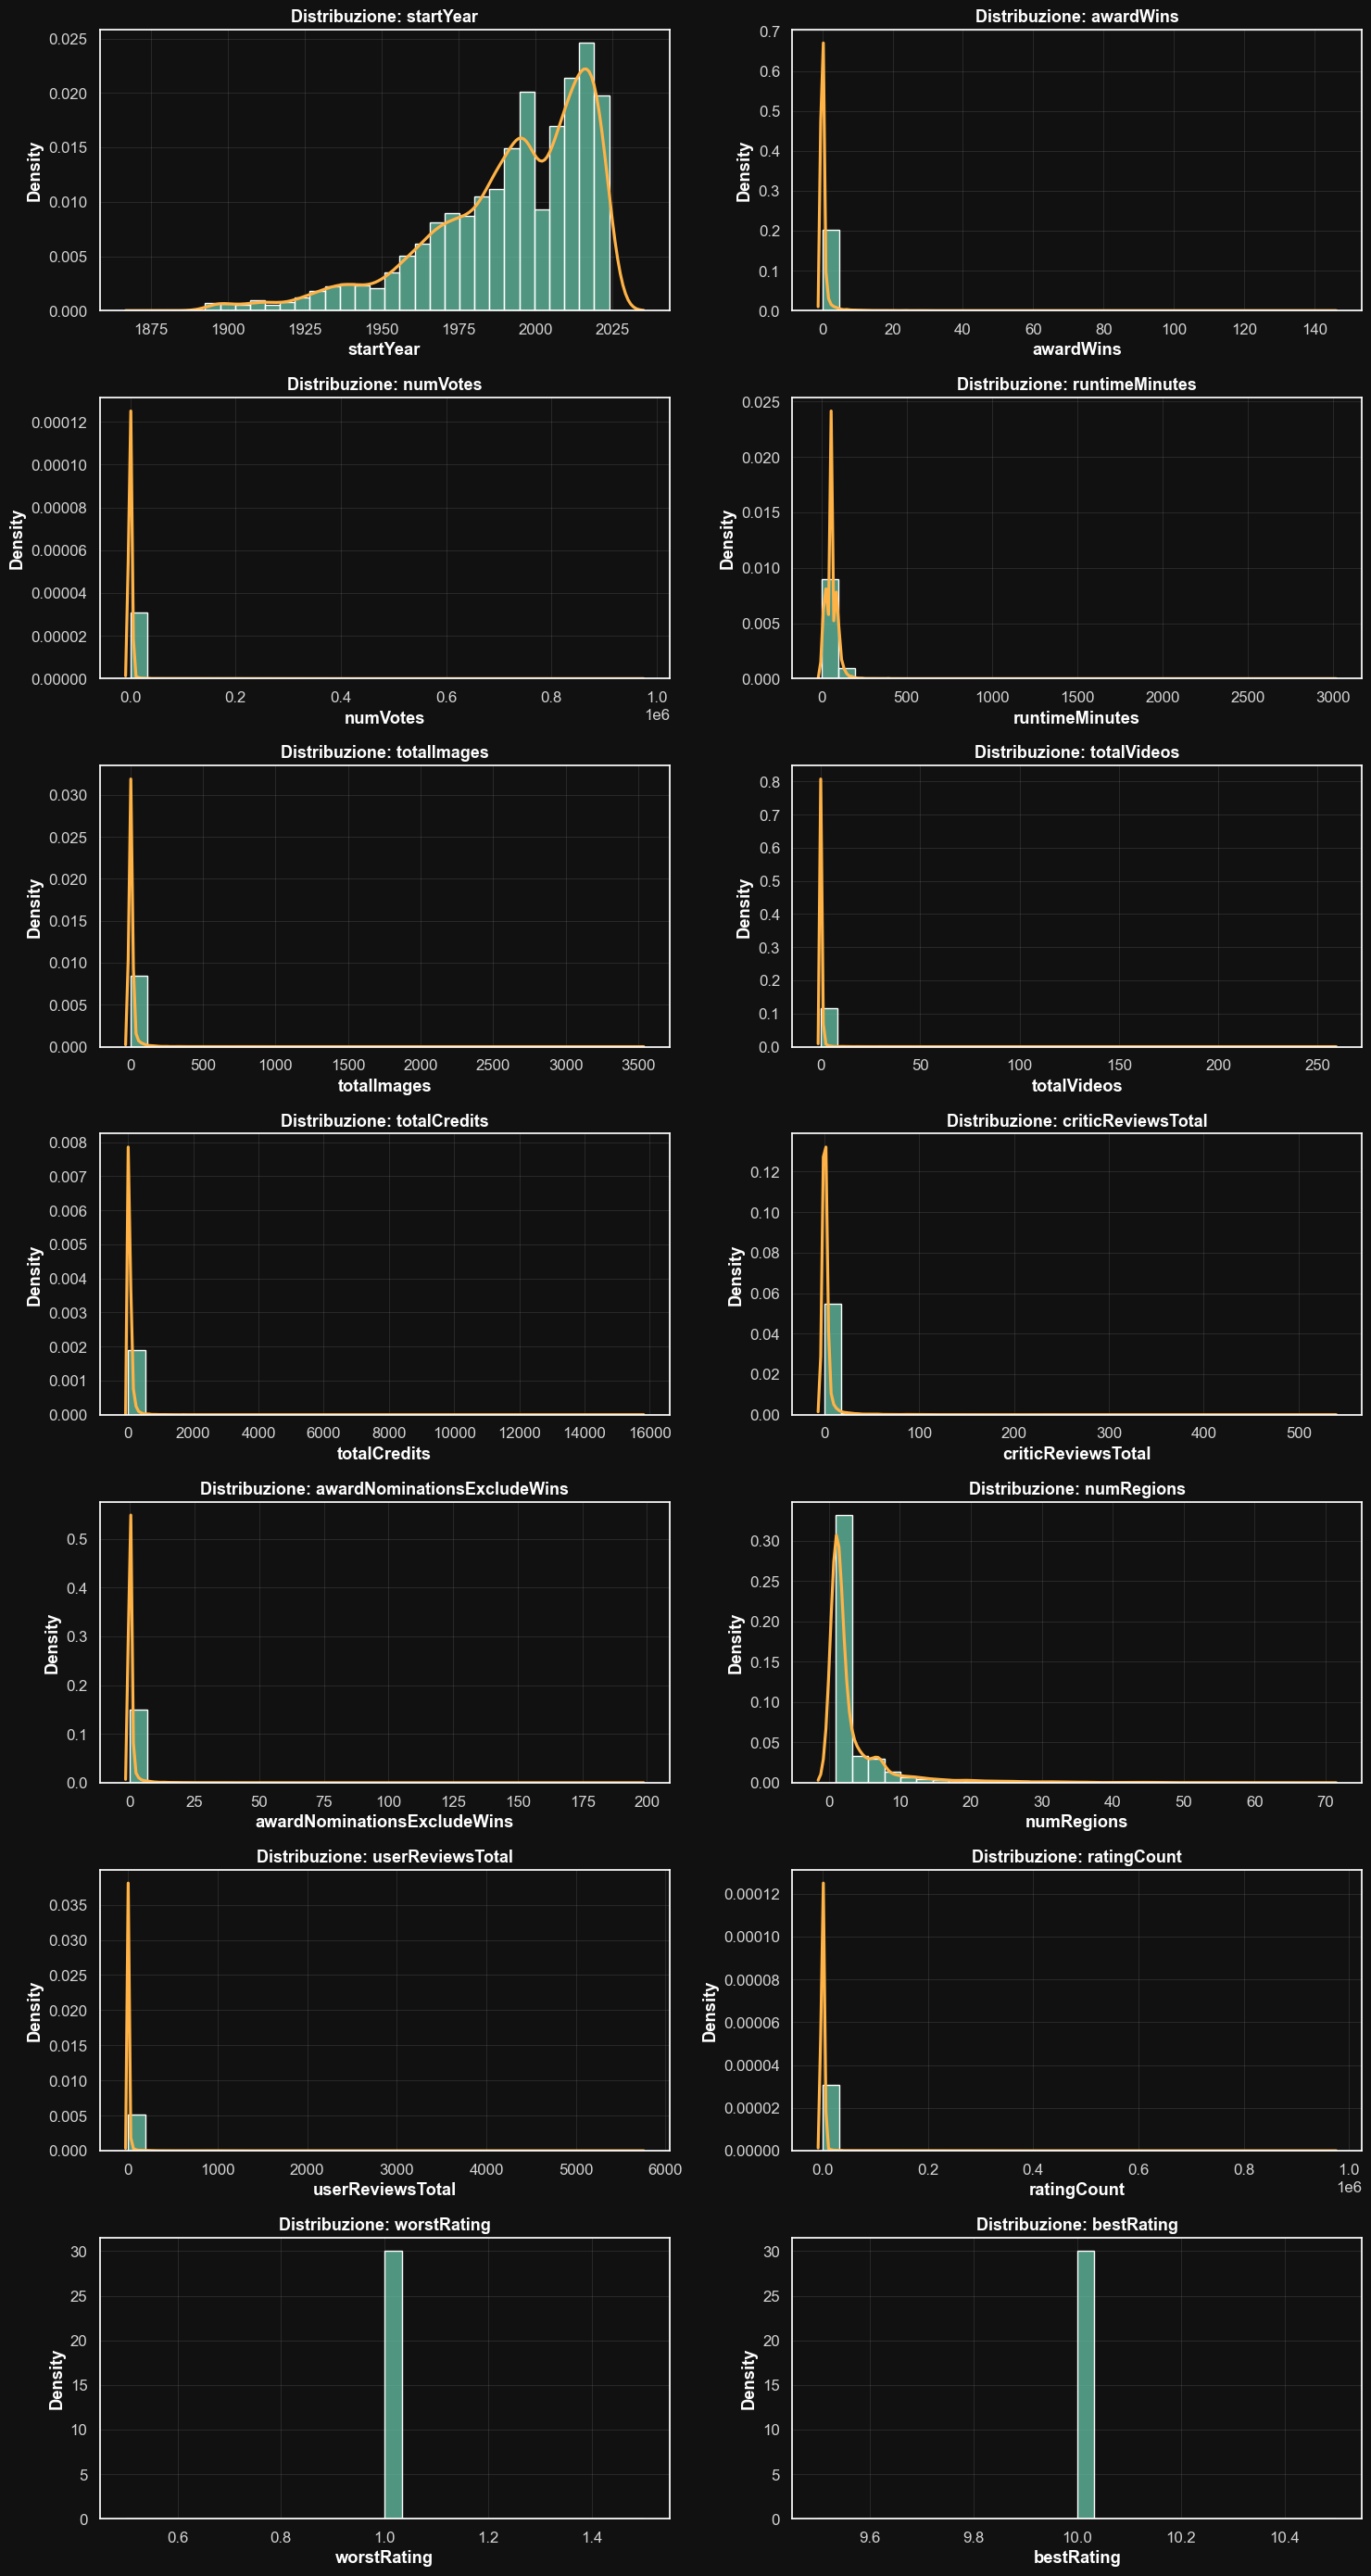

In [19]:
# Variabili numeriche
numeric_columns = ['startYear', 'awardWins', 'numVotes','runtimeMinutes',
       'totalImages', 'totalVideos', 'totalCredits', 'criticReviewsTotal',
       'awardNominationsExcludeWins', 'numRegions', 'userReviewsTotal',
       'ratingCount', 'worstRating', 'bestRating']


# Setup della griglia
n_cols = 2
n_rows = int(np.ceil(len(numeric_columns) / n_cols))
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

# Colori separati
hist_color = '#66c2a5'      # Verde acqua
kde_color = '#ffb347'       # Arancio delicato

# Plot
for idx, col in enumerate(numeric_columns):
    sns.histplot(data=df_train, x=col, ax=axes[idx], bins=30, color=hist_color, stat='density')
    sns.kdeplot(data=df_train, x=col, ax=axes[idx], color=kde_color, linewidth=2.3)
    axes[idx].set_title(f"Distribuzione: {col}")
    axes[idx].title.set_fontsize(13)
    axes[idx].title.set_weight("bold")

# Pulizia subplot extra
for j in range(idx + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [20]:
# da qui capiamo che worst rating e best rating hanno un valore unico 1 per la prima e 10 per la seconda
# possono quindi essere eliminate

df_train.drop(columns=['worstRating', 'bestRating'], inplace=True)
df_test.drop(columns=['worstRating', 'bestRating'], inplace=True)

#### CORRELAZIONI VARIABILI NUMERICHE

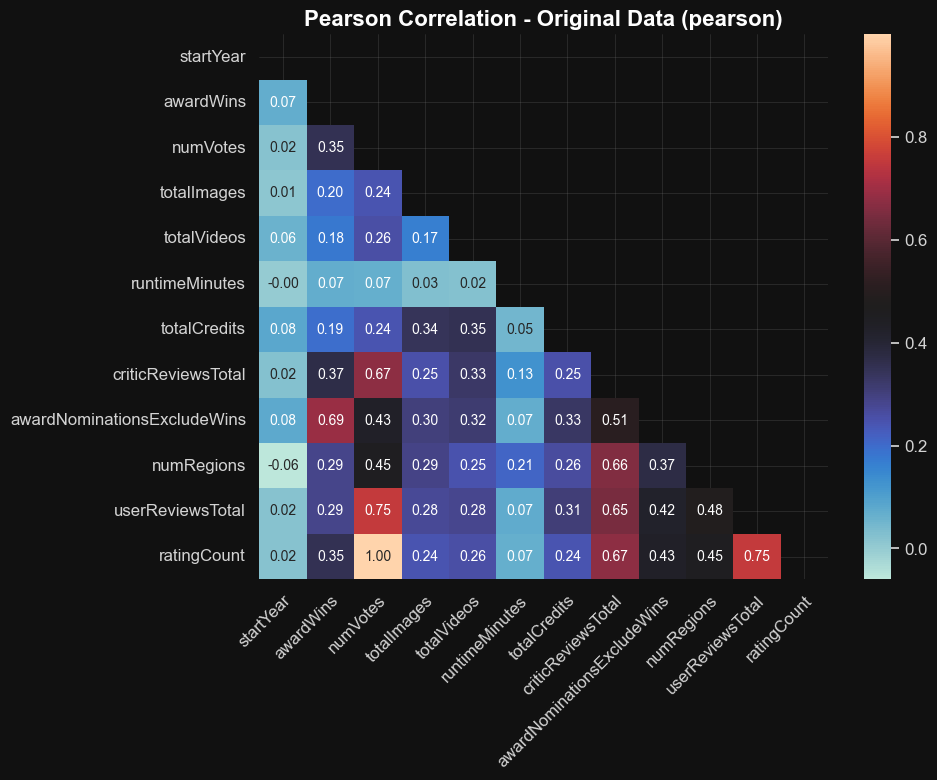

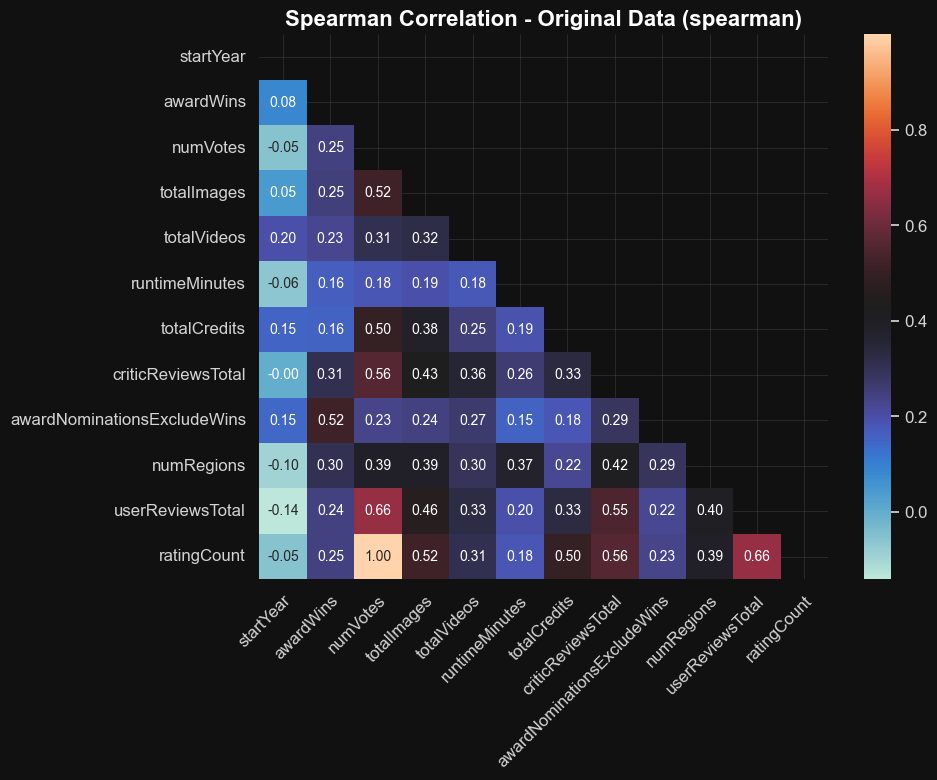

In [21]:
# --- Plotting Correlation Heatmaps for Original Numerical Variables ---

# 1. Define the list of original numerical columns to analyze
# (Excluding those we already decided to drop, like 'ratingCount')
original_numeric_cols = [
    'startYear', 'awardWins', 'numVotes', 'totalImages', 'totalVideos', 'runtimeMinutes',
    'totalCredits', 'criticReviewsTotal', 'awardNominationsExcludeWins', 'numRegions',
    'userReviewsTotal', 'ratingCount',
]

# 2. Calculate the correlation matrices on the original data
pearson_corr_original = df_train[original_numeric_cols].corr(method='pearson')
spearman_corr_original = df_train[original_numeric_cols].corr(method='spearman')


# 3. Define the plotting function (simplified version without label shortening)
def plot_correlation_heatmap(corr_matrix, index_type='pearson', title='Correlation Matrix', cmap='icefire'):
    """
    Plots a heatmap for a given correlation matrix.
    """
    # Create a boolean mask for the upper triangle
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

    # Create the figure
    plt.figure(figsize=(10, 8))

    # Create the heatmap
    sns.heatmap(
        corr_matrix,
        mask=mask,
        annot=True,
        cmap=cmap,
        fmt='.2f',
        cbar=True,  # Re-enabled the color bar as it's useful for interpretation
        annot_kws={"size": 10}
    )

    plt.title(f'{title} ({index_type})', fontsize=16, weight='bold')
    plt.xticks(rotation=45, ha="right", rotation_mode="anchor")
    plt.yticks(rotation=0)
    plt.tight_layout()
    # plt.savefig(plots_dir + f"original_{index_type}_correlation_matrix.png", dpi=300)
    plt.show()
    return


# 4. Call the function to plot the heatmaps for the original data
plot_correlation_heatmap(pearson_corr_original, index_type='pearson', title='Pearson Correlation - Original Data')
plot_correlation_heatmap(spearman_corr_original, index_type='spearman', title='Spearman Correlation - Original Data')

In [22]:
# dalle correlazioni numeriche possiamo tranquillamente eliminare ratingCount e mantenere numVotes
df_train.drop(columns=['ratingCount'], inplace=True)
df_test.drop(columns=['ratingCount'], inplace=True)

#### PRE-PROCESSING TRASFORMAZIONI VARIABILI NUMERICHE con log1p e StandardScaler

In [23]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
import numpy as np
import pandas as pd

# 1. Define the final list of numerical columns to process
cols_to_process = [
    'startYear', 'awardWins', 'numVotes', 'totalImages', 'totalVideos', 'runtimeMinutes',
    'totalCredits', 'criticReviewsTotal', 'awardNominationsExcludeWins', 'numRegions',
    'userReviewsTotal'
]

# 2. Handle missing values before transformation (using a copy to be safe)
df_train_imputed = df_train.copy()
df_test_imputed = df_test.copy()
df_train_imputed[cols_to_process] = df_train_imputed[cols_to_process].fillna(0)
df_test_imputed[cols_to_process] = df_test_imputed[cols_to_process].fillna(0)

# 3. Define the processing pipeline
log_standardize_pipeline = Pipeline([
    ('log_transform', FunctionTransformer(np.log1p)),
    ('standardize', StandardScaler())
])

# 4. Fit the pipeline ONLY on the training data and transform it
df_train_processed_data = log_standardize_pipeline.fit_transform(df_train_imputed[cols_to_process])

# 5. Transform the test data using the FITTED pipeline
df_test_processed_data = log_standardize_pipeline.transform(df_test_imputed[cols_to_process])

# 6. Create DataFrames from the processed data with clear names
processed_train_df = pd.DataFrame(
    df_train_processed_data,
    index=df_train.index,
    columns=[f'{col}_proc' for col in cols_to_process]
)

processed_test_df = pd.DataFrame(
    df_test_processed_data,
    index=df_test.index,
    columns=[f'{col}_proc' for col in cols_to_process]
)

# 7. Concatenate the new processed columns to the original DataFrames
# NOTE: We are NOT dropping the original columns anymore.
df_train = pd.concat([df_train, processed_train_df], axis=1)
df_test = pd.concat([df_test, processed_test_df], axis=1)


In [ ]:
df_train

In [ ]:
df_test

#### Rilevazione di OUTLIERS mediante LOF

Identifying outliers using Local Outlier Factor...
Number of outliers detected: 822
Applying PCA to visualize the data structure...


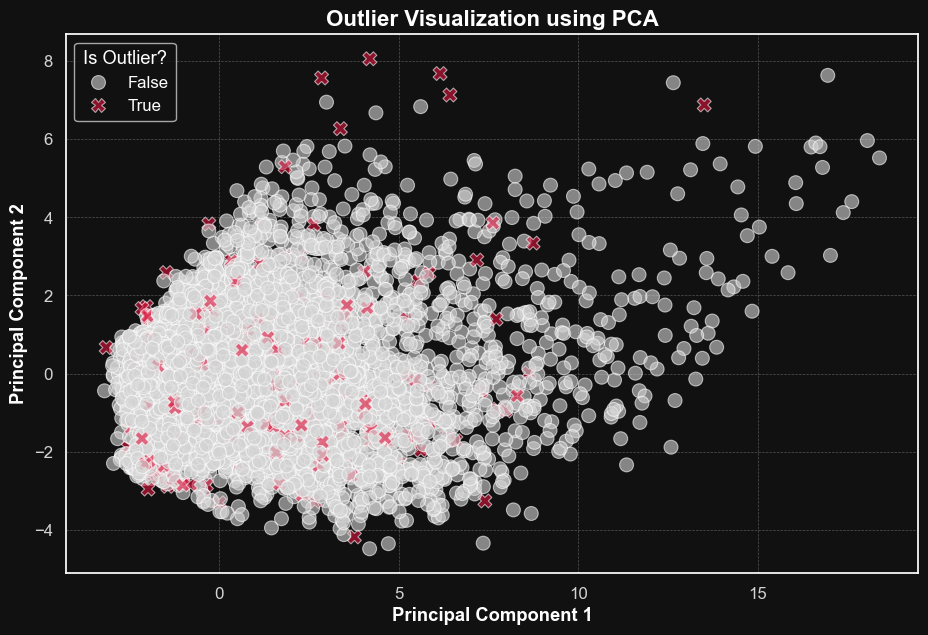

In [24]:
from sklearn.neighbors import LocalOutlierFactor
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# --- Outlier Detection and Visualization ---

# Define which columns to use for outlier detection
proc_columns = [col for col in df_train.columns if col.endswith('_proc')]

# --- Step 1: Identify Outliers on the FULL training set ---
print("Identifying outliers using Local Outlier Factor...")
lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.05, # Using the 5% we decided on
    metric='minkowski',
    p=2,
    novelty=False
)
# The 'is_outlier' Series has the same length as the original df_train
is_outlier = lof.fit_predict(df_train[proc_columns]) == -1
print(f"Number of outliers detected: {is_outlier.sum()}")


# --- Step 2: Visualize the identified outliers using PCA ---
# We apply PCA on the same data LOF was fitted on (the full df_train)
print("Applying PCA to visualize the data structure...")
pca = PCA(n_components=2, random_state=42)
data_pca = pca.fit_transform(df_train[proc_columns])

# Create a DataFrame for plotting. Its length matches the original df_train.
pca_df = pd.DataFrame(data=data_pca, columns=['PC1', 'PC2'])
# Add the outlier flag. Now the lengths match perfectly!
pca_df['is_outlier'] = is_outlier

# Plot the results
plt.figure(figsize=(11, 7))
sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='is_outlier',
    style='is_outlier',
    data=pca_df,
    s=100,
    palette={False: 'lightgray', True: 'crimson'},
    alpha=0.6
)
plt.title('Outlier Visualization using PCA', fontsize=16, weight='bold')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Is Outlier?')
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig(plots_dir + 'outlier_visualization_pca.png', dpi=300)
plt.show()


#### Eliminazione degli outliers rilevati con LOF 

In [25]:
# --- Step 3: NOW, remove the outliers from the training set ---
print(f"\nOriginal shape of df_train: {df_train.shape}")
df_train = df_train[~is_outlier]
df_train.reset_index(drop=True, inplace=True)
print(f"Shape of df_train after removing outliers: {df_train.shape}")


Original shape of df_train: (16431, 55)
Shape of df_train after removing outliers: (15609, 55)


#### Visualizziamo nuovamente le distribuzioni con le trasformazioni applicate e gli outliers rimossi

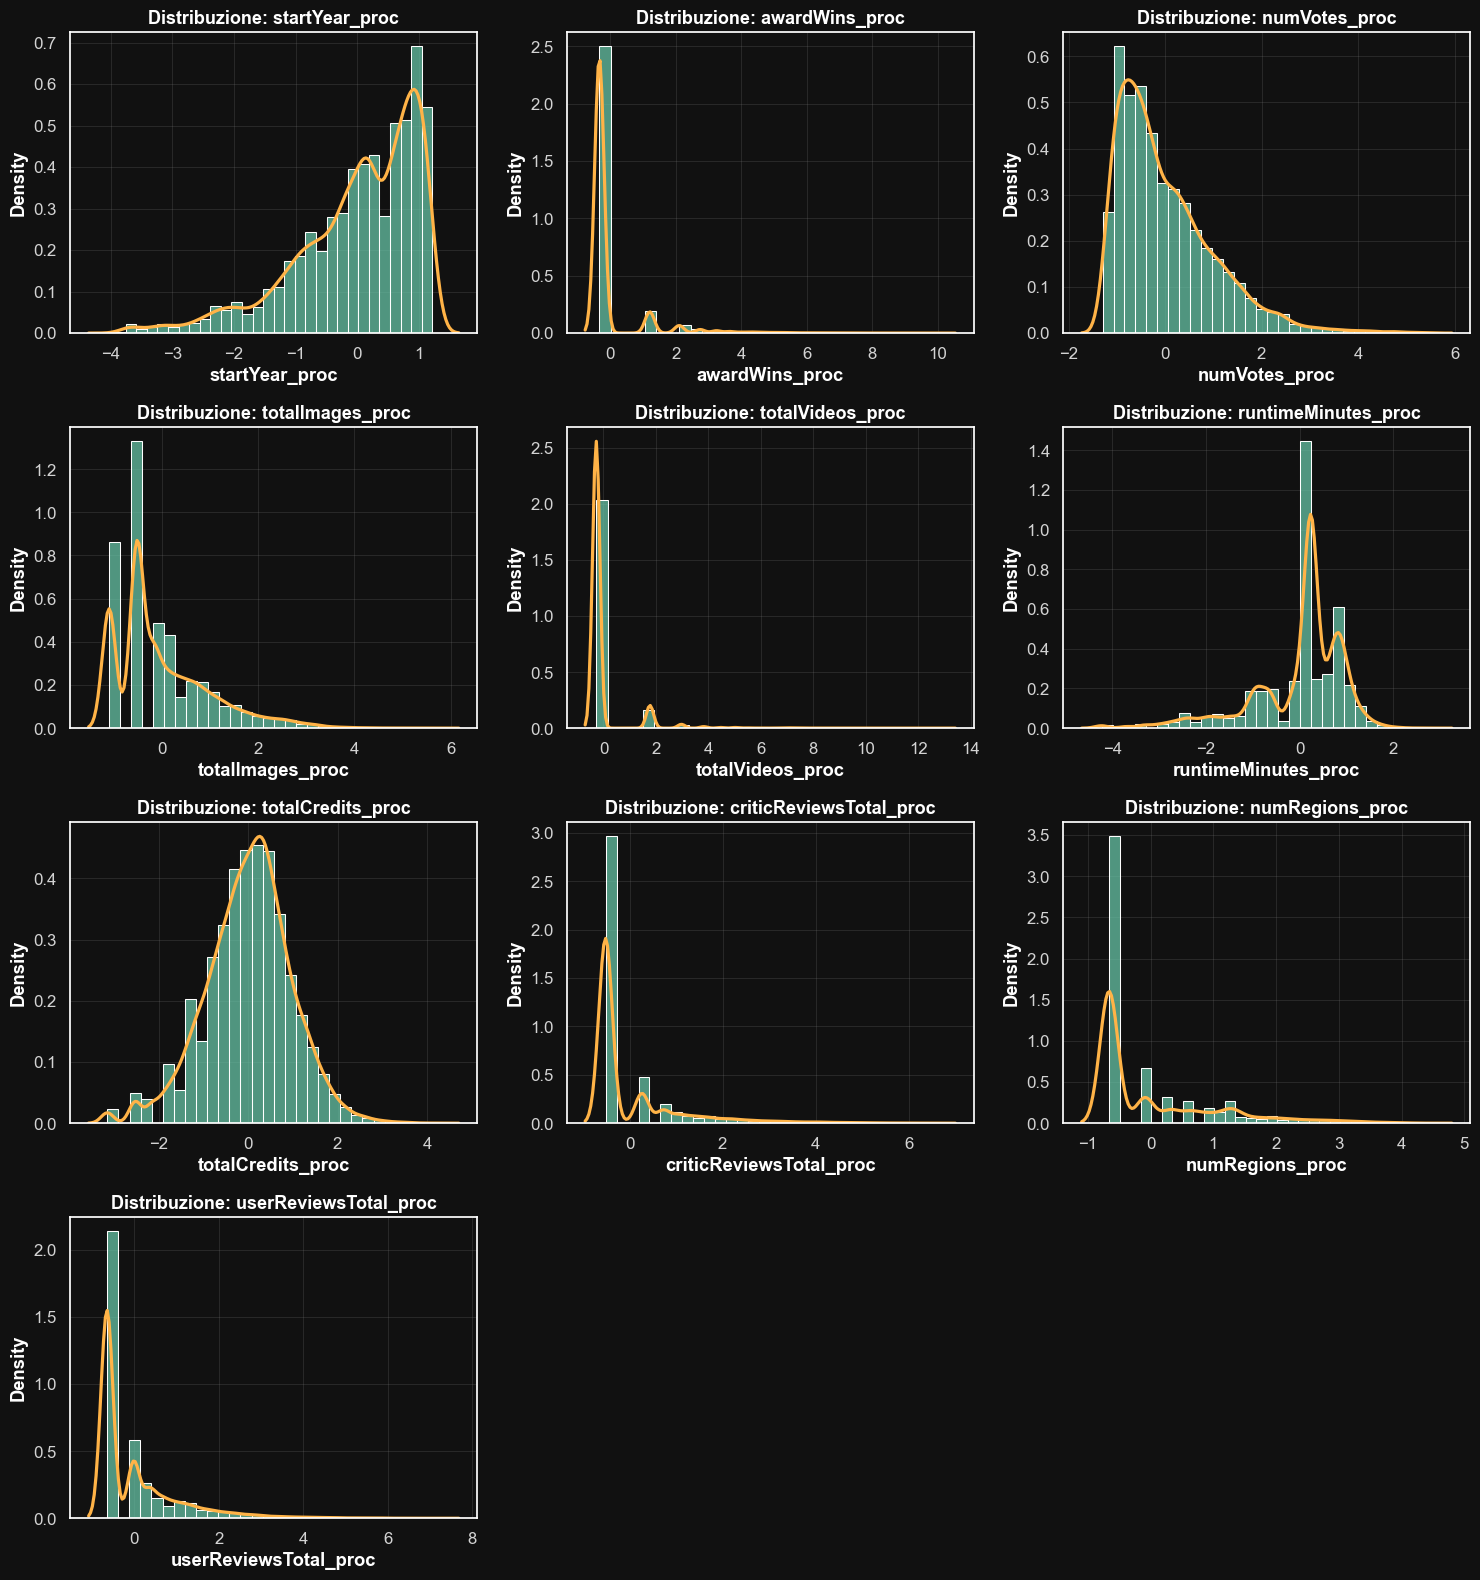

In [26]:
# plottiamo le variabili trasformate, standardizzate e con outliers rimossi
# Variabili numeriche
proc_columns = [col for col in df_train.columns if col.endswith('_proc')]
proc_columns.remove('awardNominationsExcludeWins_proc')

# Setup della griglia
n_cols = 3
n_rows = int(np.ceil(len(proc_columns) / n_cols))
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

# Colori separati
hist_color = '#66c2a5'      # Verde acqua
kde_color = '#ffb347'       # Arancio delicato

# Plot
for idx, col in enumerate(proc_columns):
    sns.histplot(data=df_train, x=col, ax=axes[idx], bins=30, color=hist_color, stat='density')
    sns.kdeplot(data=df_train, x=col, ax=axes[idx], color=kde_color, linewidth=2.3)
    axes[idx].set_title(f"Distribuzione: {col}")
    axes[idx].title.set_fontsize(13)
    axes[idx].title.set_weight("bold")

# Pulizia subplot extra
for j in range(idx + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig(plots_dir + "transformed_variables_distribution.png", dpi=300)
plt.show()

#### Final adjustments

In [27]:
# --- Convert 'rating_encoded' from float to integer ---

# This is done for both dataframes to maintain consistency
df_train['rating_encoded'] = df_train['rating_encoded'].astype(int)
df_test['rating_encoded'] = df_test['rating_encoded'].astype(int)

print("Data type for 'rating_encoded' has been converted to integer.")

Data type for 'rating_encoded' has been converted to integer.


In [28]:
df_train.head()

,originalTitle,startYear,endYear,runtimeMinutes,awardWins,numVotes,totalImages,totalVideos,totalCredits,criticReviewsTotal,...,awardWins_proc,numVotes_proc,totalImages_proc,totalVideos_proc,runtimeMinutes_proc,totalCredits_proc,criticReviewsTotal_proc,awardNominationsExcludeWins_proc,numRegions_proc,userReviewsTotal_proc
0,Neogenic Nightmare Chapter 3: Hydro-Man,1995,\N,58,0,779,1,0,21,1,...,-0.33267,1.465542,-0.510552,-0.277418,0.236295,-0.367632,0.264517,-0.316269,-0.661879,-0.648047
1,Looping,1982,\N,58,0,11,1,0,1,0,...,-0.33267,-0.906068,-0.510552,-0.277418,0.236295,-2.524145,-0.517037,-0.316269,-0.661879,-0.648047
2,Idealnaya para,1992,\N,58,0,38,1,0,24,0,...,-0.33267,-0.236435,-0.510552,-0.277418,0.236295,-0.252666,-0.517037,-0.316269,-0.661879,-0.015936
3,MasterChef Celebrity México,2021,\N,58,0,15,22,0,56,0,...,-0.33267,-0.742626,1.535001,-0.277418,0.236295,0.488544,-0.517037,-0.316269,-0.661879,-0.648047
4,Lightdance,1995,\N,34,0,14,1,0,0,0,...,-0.33267,-0.779293,-0.510552,-0.277418,-0.452128,-3.147517,-0.517037,-0.316269,-0.661879,-0.015936


In [29]:
df_test.head()

,originalTitle,startYear,endYear,runtimeMinutes,awardWins,numVotes,totalImages,totalVideos,totalCredits,criticReviewsTotal,...,awardWins_proc,numVotes_proc,totalImages_proc,totalVideos_proc,runtimeMinutes_proc,totalCredits_proc,criticReviewsTotal_proc,awardNominationsExcludeWins_proc,numRegions_proc,userReviewsTotal_proc
0,Geologist of Animal Collective Performs Live a...,2015,\N,21,0,15,7,2,11,0,...,-0.33267,-0.742626,0.650519,2.972334,-1.064242,-0.912751,-0.517037,-0.316269,-0.661879,-0.648047
1,Shan gou 1999,1999,\N,58,0,304,10,0,40,9,...,-0.33267,0.932074,0.917236,-0.277418,0.236295,0.192232,2.079227,-0.316269,0.633799,1.355697
2,The Craftsman: Preserving the Last Higgins Boat,2023,\N,58,0,10,2,0,6,0,...,-0.33267,-0.955502,-0.170960,-0.277418,0.236295,-1.397490,-0.517037,-0.316269,-0.661879,-0.648047
3,Week 3: Tuesday,2020,\N,58,0,11,0,0,52,0,...,-0.33267,-0.906068,-1.091087,-0.277418,0.236295,0.423109,-0.517037,-0.316269,-0.661879,-0.648047
4,Traumhaus,1999,\N,90,0,145,2,0,44,1,...,-0.33267,0.513527,-0.170960,-0.277418,0.807562,0.275951,0.264517,-0.316269,-0.661879,-0.648047


#### Salvataggio del dataset

In [30]:
# --- Step 8: Save the Prepared Datasets ---

# Define output file paths
output_train_path = os.path.join(dataset_dir, 'train_prepared.csv')
output_test_path = os.path.join(dataset_dir, 'test_prepared.csv')

try:
    # Save the processed dataframes to new CSV files
    # index=False prevents pandas from writing the dataframe index as a column
    df_train.to_csv(output_train_path, index=False)
    print(f"Processed training data saved successfully to: {output_train_path}")

    df_test.to_csv(output_test_path, index=False)
    print(f"Processed testing data saved successfully to: {output_test_path}")

except Exception as e:
    print(f"An error occurred while saving the files: {e}")

Processed training data saved successfully to: dataset/train_prepared.csv
Processed testing data saved successfully to: dataset/test_prepared.csv
